# Influencer vs Observer Classification Challenge

- **Team:** Lucas de Oliveira Martim, Ivan Bertaux, Loïc Clotteau
- **Goal:** Predict social media user roles based on tweet content and user features
- **Competition:** CSC_51054_EP Data Challenge
- **Date:** November/December (2025)
---
- **83.4%** accuracy on Kaggle leaderboard
- **20.4%** improvement over baseline (63%)
---

## 1. Environment Setup

Installing and importing all necessary libraries for our analysis.

In [42]:
import json
import numpy as np
import pandas as pd
from pandas import json_normalize
import pickle
import re
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import CamembertTokenizer, CamembertModel
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
import os
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## 1. Data pre-processing
This shows how to get features.pkl from jsonl files

### 1.1.1 From jsonl to pkl

This section shows how we converted jsonl files to pkl.
It was done because jsonl was taking too long to load and it had to reprocess full_text vs extended_tweet.full_text every session (boring repetitive task)

In [43]:
def extract_full_text(tweet):
    text = tweet['text']
    if not pd.isna(tweet['extended_tweet.full_text']):
        text = tweet['extended_tweet.full_text']
    return text

train_data = pd.read_json('train.jsonl', lines=True)
kaggle_data = pd.read_json('kaggle_test.jsonl', lines=True)
train_data = json_normalize(train_data.to_dict(orient='records'))
kaggle_data = json_normalize(kaggle_data.to_dict(orient='records'))

train_data['full_text'] = train_data.apply(lambda tweet: extract_full_text(tweet), axis=1)
kaggle_data['full_text'] = kaggle_data.apply(lambda tweet: extract_full_text(tweet), axis=1)

In [44]:
# This function was used to remove meaningless data from
# source. We decided it was better to only store the actual 
# platform source name.

def extract_source_platform(source_html):
    """Extract platform name from Twitter source HTML"""
    if pd.isna(source_html):
        return 'unknown'
    
    match = re.search(r'>([^<]+)<', source_html)
    if match:
        platform = match.group(1).strip()
        
        # Clean up common patterns
        platform = platform.replace('Twitter for ', '')
        platform = platform.replace('Twitter Web ', '')
        
        return platform.lower()
    
    # If no match, try to extract from URL
    url_patterns = {
        'iphone': 'iphone',
        'ipad': 'ipad',
        'android': 'android',
        'mobile.twitter.com': 'mobile web',
        'twitter.com': 'web',
        'publicize.wp.com': 'wordpress',
        'tweetdeck': 'tweetdeck',
        'instagram': 'instagram',
        'foursquare': 'foursquare'
    }
    
    source_lower = source_html.lower()
    for pattern, name in url_patterns.items():
        if pattern in source_lower:
            return name
    
    return 'other'

# Apply the extraction
train_data['source'] = train_data['source'].apply(extract_source_platform)
kaggle_data['source'] = kaggle_data['source'].apply(extract_source_platform)

# Check the results
print(train_data['source'].value_counts())
print(kaggle_data['source'].value_counts())

source
iphone            49536
app               45072
android           44903
ipad               3520
tweetdeck          2558
                  ...  
polyalert-live        1
publer.io             1
tic mag               1
mytwt_mycron          1
fcm live tweet        1
Name: count, Length: 408, dtype: int64
source
iphone                  33530
app                     29723
android                 29714
ipad                     2445
tweetdeck                1737
                        ...  
lamariejeanne media         1
zut-dev                     1
itfb                        1
andstatus-opensource        1
echofon                     1
Name: count, Length: 278, dtype: int64


In [45]:
# After some database analysis we found out that those
# were the collumns that contained possible meaningfull data.
# it is now much less than the previous 194 features

columns_to_keep = [
    'created_at',
    'source',
    'is_quote_status',
    'challenge_id',
    'label',
    'entities.urls',
    'entities.user_mentions',
    'entities.symbols',
    'user.profile_image_url_https',
    'user.listed_count',
    'user.profile_background_image_url',
    'user.favourites_count',
    'user.description',
    'user.created_at',
    'user.is_translator',
    'user.profile_background_image_url_https',
    'user.profile_link_color',
    'user.translator_type',
    'user.geo_enabled',
    'user.profile_background_color',
    'user.profile_sidebar_border_color',
    'user.profile_text_color',
    'user.profile_image_url',
    'user.profile_background_tile',
    'user.profile_banner_url',
    'user.statuses_count',
    'user.profile_use_background_image',
    'user.default_profile',
    'user.location',
    'user.profile_sidebar_fill_color',
    'extended_tweet.entities.urls',
    'extended_tweet.entities.user_mentions',
    'full_text',
]

train_data = train_data[[col for col in columns_to_keep if col in train_data.columns]]
kaggle_data = kaggle_data[[col for col in columns_to_keep if col in kaggle_data.columns]]

train_data.to_pickle('train_filtered.pkl')
kaggle_data.to_pickle('kaggle_filtered.pkl')

print("Data saved successfully!")

Data saved successfully!


### 1.1.2 Creating features.pkl

After data cleaning we'll select only the features that we judge to be helpfull to the tweet classification and use camemBERT to extract the embedding from text inputs.

This will be done to both trainning and kaggle datasets.

The embedded texts will be the input to our model

In [52]:
# Configuration
TEXT_FEATURES = ['full_text', 'source', 'user.location', 'user.description']
NUMERICAL_FEATURES = ['user.statuses_count', 'user.favourites_count', 'user.listed_count']
MAX_LENGTH = 280
BATCH_SIZE = 16

# Embedding extraction function
def extract_embeddings(texts, tokenizer, model, device, max_length=128, batch_size=32, desc="Extracting"):
    """Extract CamemBERT embeddings for a list of texts"""
    embeddings = []
    
    for i in tqdm(range(0, len(texts), batch_size), desc=desc):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(batch, padding=True, truncation=True, 
                           max_length=max_length, return_tensors='pt')
        
        with torch.no_grad():
            outputs = model(
                input_ids=encoded['input_ids'].to(device),
                attention_mask=encoded['attention_mask'].to(device)
            )
            embeddings.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())
    
    return np.vstack(embeddings)

# Check if features already exist
if os.path.exists('features.pkl'):
    print("Features already extracted. Skip to Section 3 to load them.")
else:
    print("Starting feature extraction...")
    
    X_train = pd.read_pickle('data_train.pkl')
    X_kaggle = pd.read_pickle('data_kaggle.pkl')
    y_train = X_train['label']
    
    # Fill missing values
    for df in [X_train, X_kaggle]:
        for col in TEXT_FEATURES:
            df[col] = df[col].fillna('unknown' if col != 'full_text' else '')
        for col in NUMERICAL_FEATURES:
            df[col] = df[col].fillna(0)
    
    print("Data loaded and cleaned")
    print("Loading CamemBERT...")
    tokenizer = CamembertTokenizer.from_pretrained('camembert-base')
    camembert = CamembertModel.from_pretrained('camembert-base')
    camembert.to(device)
    camembert.eval()
    
    for param in camembert.parameters():
        param.requires_grad = False
    
    print("CamemBERT loaded")
    print("\nExtracting text embeddings...")
    
    train_embeddings = []
    kaggle_embeddings = []
    
    for feature in TEXT_FEATURES:
        print(f"\nProcessing '{feature}'...")
        train_emb = extract_embeddings(
            X_train[feature].tolist(), tokenizer, camembert, device,
            max_length=MAX_LENGTH, batch_size=BATCH_SIZE, desc=f"  Train"
        )
        kaggle_emb = extract_embeddings(
            X_kaggle[feature].tolist(), tokenizer, camembert, device,
            max_length=MAX_LENGTH, batch_size=BATCH_SIZE, desc=f"  Kaggle"
        )
        train_embeddings.append(train_emb)
        kaggle_embeddings.append(kaggle_emb)
        print(f"Shape: {train_emb.shape}")
    
    # Free up GPU memory
    del camembert, tokenizer
    torch.cuda.empty_cache()
    
    print("\nText embeddings extracted")
    print("\nProcessing numerical features...")
    scaler = StandardScaler()
    train_numerical = scaler.fit_transform(X_train[NUMERICAL_FEATURES].values)
    kaggle_numerical = scaler.transform(X_kaggle[NUMERICAL_FEATURES].values)
    print("Numerical features scaled")
    print("\nCombining and saving features...")
    
    X_train_combined = np.hstack(train_embeddings + [train_numerical])
    X_kaggle_combined = np.hstack(kaggle_embeddings + [kaggle_numerical])
    
    # Save everything to a single file
    with open('features.pkl', 'wb') as f:
        pickle.dump({
            'X_train': X_train_combined,
            'y_train': y_train.values,
            'X_kaggle': X_kaggle_combined,
            'kaggle_ids': X_kaggle['challenge_id'].values,
            'scaler': scaler
        }, f)
    
    print(f"\n{'='*70}")
    print("FEATURES SAVED SUCCESSFULLY!")
    print(f"  Train shape: {X_train_combined.shape}")
    print(f"  Kaggle shape: {X_kaggle_combined.shape}")
    print(f"  Total features: {X_train_combined.shape[1]}")
    print(f"  File: features.pkl")
    print(f"{'='*70}")

Starting feature extraction...
Data loaded and cleaned
Loading CamemBERT...
CamemBERT loaded

Extracting text embeddings...

Processing 'full_text'...


  Train:  12%|█▏        | 1209/9683 [00:46<05:24, 26.12it/s]

## 2. Load features.pkl

Load all pre extracted embedding and other data so we can quickly start our trainning.

In [53]:
from sklearn.model_selection import train_test_split

print("Loading features...")
with open('features.pkl', 'rb') as f:
    data = pickle.load(f)

X_train_full = data['X_train']
y_train_full = data['y_train']
X_kaggle = data['X_kaggle']
kaggle_ids = data['kaggle_ids']

# Split into train and validation (80/20)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_train_full
)

print(f"Features loaded and split")
print(f"Full Train:  {X_train_full.shape}")
print(f"Train (80%): {X_train.shape}")
print(f"Val (20%):   {X_val.shape}")
print(f"Kaggle:      {X_kaggle.shape}")
print(f"Labels:      {y_train_full.shape}")
print(f"\nTrain labels distribution: {np.bincount(y_train)}")
print(f"Val labels distribution:   {np.bincount(y_val)}")

Loading features...


KeyboardInterrupt: 

## 3. FCNN Model
This model achieved 79.7% in kaggle accuracy

In [33]:
BATCH_SIZE = 32
LEARNING_RATE = 0.001
NUM_EPOCHS = 30
HIDDEN_DIMS = [256, 128, 64]
DROPOUT = 0.1

print("Training Configuration:")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  Architecture: {X_train.shape[1]} -> {' -> '.join(map(str, HIDDEN_DIMS))} -> 2")

Training Configuration:
  Batch size: 32
  Learning rate: 0.001
  Epochs: 30
  Architecture: 3075 -> 256 -> 128 -> 64 -> 2


In [ ]:
class TweetDataset(Dataset):
    def __init__(self, features, labels=None):
        self.features = torch.FloatTensor(features)
        self.labels = torch.LongTensor(labels) if labels is not None else None
    
    def __len__(self):
        return len(self.features)
    
    def __getitem__(self, idx):
        if self.labels is not None:
            return self.features[idx], self.labels[idx]
        return self.features[idx]

# Create datasets for train and validation
train_dataset = TweetDataset(X_train, y_train)
val_dataset = TweetDataset(X_val, y_val)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Data loaders ready")
print(f"Train: {len(train_loader)} batches ({len(train_dataset)} samples)")
print(f"Val:   {len(val_loader)} batches ({len(val_dataset)} samples)")

✓ Data loaders ready
  Train: 3873 batches (123931 samples)
  Val:   969 batches (30983 samples)


In [ ]:
class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout):
        super().__init__()
        layers = []
        prev_dim = input_dim
        
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.ReLU(),
                nn.BatchNorm1d(hidden_dim),
                nn.Dropout(dropout)
            ])
            prev_dim = hidden_dim
        
        layers.append(nn.Linear(prev_dim, 2))
        self.network = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.network(x)

model = FCNN(X_train.shape[1], HIDDEN_DIMS, DROPOUT).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

print(f"Model initialized ({sum(p.numel() for p in model.parameters()):,} parameters)")

✓ Model initialized (829,634 parameters)


In [36]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    batch_losses = []  # Track loss per batch for detailed analysis
    
    for features, labels in tqdm(loader, desc="Training"):
        features, labels = features.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        batch_losses.append(loss.item())
        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    return total_loss / len(loader), correct / total, batch_losses

def validate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    
    with torch.no_grad():
        for features, labels in tqdm(loader, desc="Validating"):
            features, labels = features.to(device), labels.to(device)
            
            outputs = model(features)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    return total_loss / len(loader), correct / total

### Training FCNN

In [ ]:
print(f"\nTraining for {NUM_EPOCHS} epochs...")
print("="*70)

# Initialize training history
history = {
    'epoch': [],
    'train_loss': [],
    'train_accuracy': [],
    'val_loss': [],
    'val_accuracy': [],
    'learning_rate': [],
    'batch_losses': []  # Store all batch losses for detailed plots
}

best_val_acc = 0
best_epoch = 0
for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    
    # Training phase
    train_loss, train_acc, batch_losses = train_epoch(model, train_loader, criterion, optimizer, device)
    
    # Validation phase
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    
    # Store metrics in history
    history['epoch'].append(epoch + 1)
    history['train_loss'].append(train_loss)
    history['train_accuracy'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)
    history['learning_rate'].append(optimizer.param_groups[0]['lr'])
    history['batch_losses'].extend(batch_losses)
    
    print(f"Train - Loss: {train_loss:.4f} | Acc: {train_acc*100:.2f}%")
    print(f"Val   - Loss: {val_loss:.4f} | Acc: {val_acc*100:.2f}% | LR: {optimizer.param_groups[0]['lr']:.6f}")
    
    # Use validation loss for scheduler
    scheduler.step(val_loss)
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        torch.save(model.state_dict(), 'best_model.pth')
        print(f"✓ Best model saved (val_acc: {best_val_acc*100:.2f}%)")

# Save training history
with open('training_history.pkl', 'wb') as f:
    pickle.dump(history, f)

print(f"\n{'='*70}")
print(f"Training complete!")
print(f"  Best validation accuracy: {best_val_acc*100:.2f}% (epoch {best_epoch})")
print(f"  Final train accuracy: {history['train_accuracy'][-1]*100:.2f}%")
print(f"  Final val accuracy: {history['val_accuracy'][-1]*100:.2f}%")
print(f"  Overfitting gap: {(history['train_accuracy'][-1] - history['val_accuracy'][-1])*100:.2f}%")
print(f"Training history saved to 'training_history.pkl'")
print(f"{'='*70}")


Training for 30 epochs...

Epoch 1/30


Validating: 100%|██████████| 969/969 [00:00<00:00, 1360.83it/s]


Train - Loss: 0.4480 | Acc: 79.50%
Val   - Loss: 0.4197 | Acc: 80.78% | LR: 0.001000
✓ Best model saved (val_acc: 80.78%)

Epoch 2/30


Validating: 100%|██████████| 969/969 [00:00<00:00, 1417.79it/s]


Train - Loss: 0.4169 | Acc: 81.36%
Val   - Loss: 0.3960 | Acc: 82.83% | LR: 0.001000
✓ Best model saved (val_acc: 82.83%)

Epoch 3/30


Validating: 100%|██████████| 969/969 [00:00<00:00, 1448.59it/s]


... (51 outputs left out)

Validating: 100%|██████████| 969/969 [00:00<00:00, 1283.28it/s]


Train - Loss: 0.2453 | Acc: 90.06%
Val   - Loss: 0.4842 | Acc: 87.96% | LR: 0.000125
✓ Best model saved (val_acc: 87.96%)

Epoch 30/30


Validating: 100%|██████████| 969/969 [00:00<00:00, 1400.68it/s]

Train - Loss: 0.2422 | Acc: 90.24%
Val   - Loss: 0.3046 | Acc: 87.35% | LR: 0.000063

Training complete!
  Best validation accuracy: 87.96% (epoch 29)
  Final train accuracy: 90.24%
  Final val accuracy: 87.35%
  Overfitting gap: 2.89%
✓ Training history saved to 'training_history.pkl'


### Training Visualization

Plotting training metrics to analyze model performance over epochs.

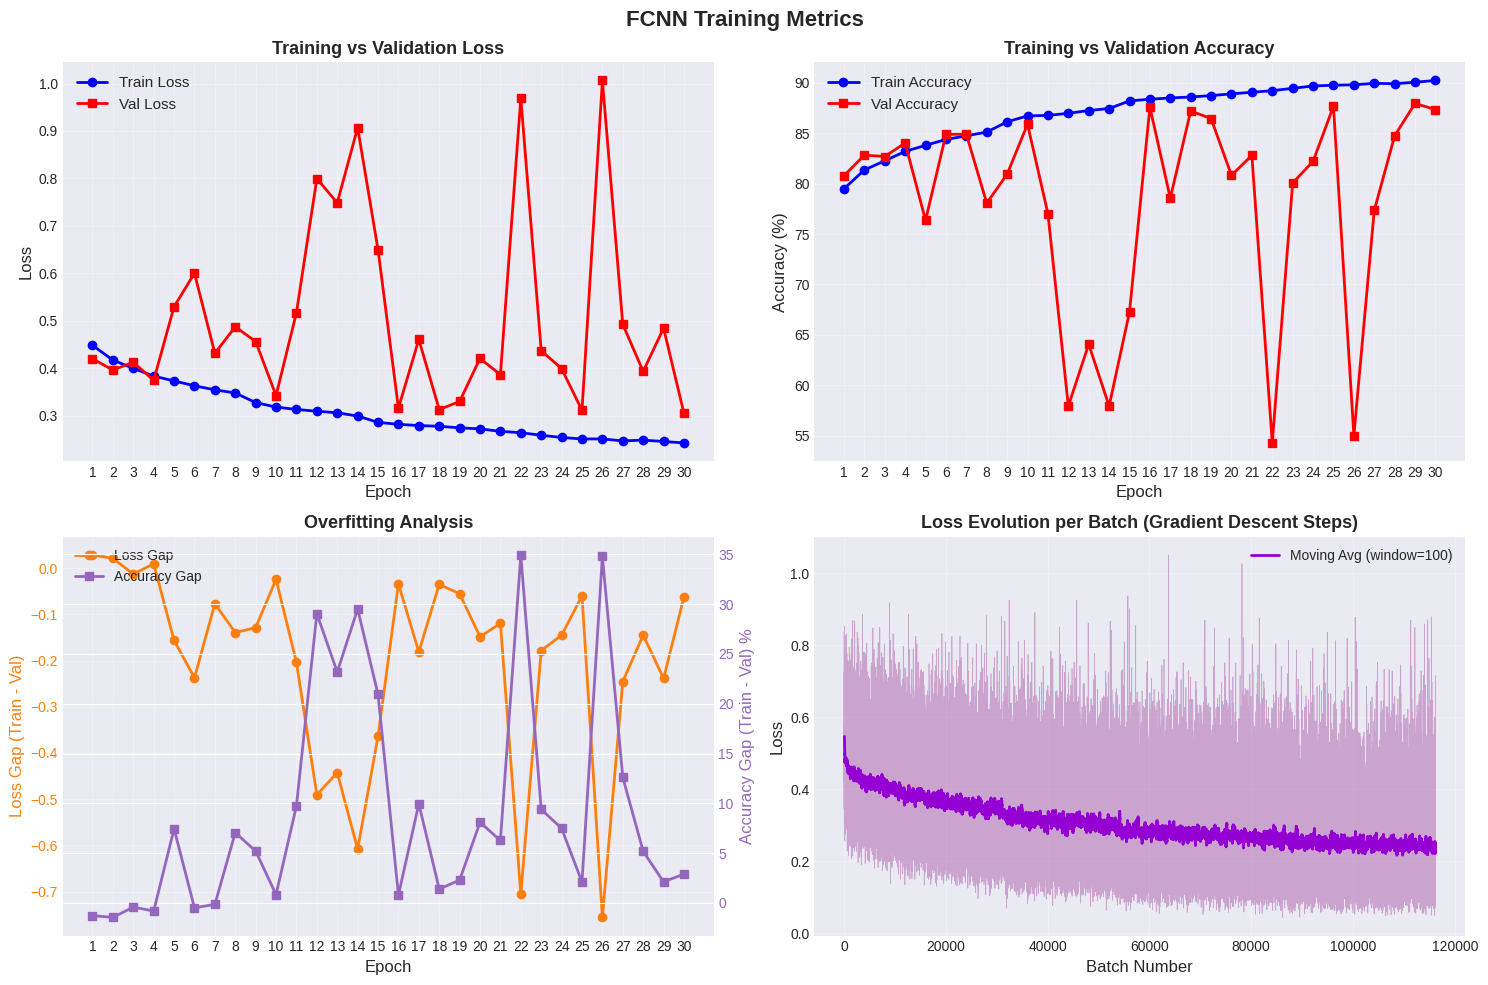


Training Metrics Summary:
Initial Train Loss:     0.4480
Final Train Loss:       0.2422
Final Val Loss:         0.3046

Initial Train Accuracy: 79.50%
Final Train Accuracy:   90.24%
Best Val Accuracy:      87.96%
Final Val Accuracy:     87.35%

Overfitting Gap (Final):
  Loss Gap:     -0.0624
  Accuracy Gap: 2.89%

Total Epochs:     30
Total Batches:    116190
✓ Plots saved as 'fcnn_training_metrics.png'


In [41]:
# Load training history (if running this separately from training)
if 'history' not in locals():
    with open('training_history.pkl', 'rb') as f:
        history = pickle.load(f)

# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('FCNN Training Metrics', fontsize=16, fontweight='bold')

# Plot 1: Training vs Validation Loss
axes[0, 0].plot(history['epoch'], history['train_loss'], 'b-', linewidth=2, marker='o', label='Train Loss')
axes[0, 0].plot(history['epoch'], history['val_loss'], 'r-', linewidth=2, marker='s', label='Val Loss')
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Loss', fontsize=12)
axes[0, 0].set_title('Training vs Validation Loss', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xticks(history['epoch'])

# Plot 2: Training vs Validation Accuracy
axes[0, 1].plot(history['epoch'], [acc * 100 for acc in history['train_accuracy']], 
                'b-', linewidth=2, marker='o', label='Train Accuracy')
axes[0, 1].plot(history['epoch'], [acc * 100 for acc in history['val_accuracy']], 
                'r-', linewidth=2, marker='s', label='Val Accuracy')
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('Accuracy (%)', fontsize=12)
axes[0, 1].set_title('Training vs Validation Accuracy', fontsize=13, fontweight='bold')
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_xticks(history['epoch'])

# Plot 3: Overfitting Analysis (Gap between Train and Val)
overfitting_gap_loss = [train - val for train, val in zip(history['train_loss'], history['val_loss'])]
overfitting_gap_acc = [(train - val) * 100 for train, val in zip(history['train_accuracy'], history['val_accuracy'])]

ax3 = axes[1, 0]
color = 'tab:orange'
ax3.set_xlabel('Epoch', fontsize=12)
ax3.set_ylabel('Loss Gap (Train - Val)', color=color, fontsize=12)
line1 = ax3.plot(history['epoch'], overfitting_gap_loss, color=color, linewidth=2, 
                 marker='o', label='Loss Gap')
ax3.tick_params(axis='y', labelcolor=color)
ax3.grid(True, alpha=0.3)
ax3.set_xticks(history['epoch'])

ax3_twin = ax3.twinx()
color = 'tab:purple'
ax3_twin.set_ylabel('Accuracy Gap (Train - Val) %', color=color, fontsize=12)
line2 = ax3_twin.plot(history['epoch'], overfitting_gap_acc, color=color, linewidth=2, 
                      marker='s', label='Accuracy Gap')
ax3_twin.tick_params(axis='y', labelcolor=color)

ax3.set_title('Overfitting Analysis', fontsize=13, fontweight='bold')
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax3.legend(lines, labels, loc='upper left', fontsize=10)

# Plot 4: Batch Loss Evolution (showing trend across all batches)
batch_numbers = list(range(1, len(history['batch_losses']) + 1))
axes[1, 1].plot(batch_numbers, history['batch_losses'], 'purple', alpha=0.3, linewidth=0.5)
# Add smoothed trend line (moving average)
window_size = 100
if len(history['batch_losses']) >= window_size:
    smoothed = np.convolve(history['batch_losses'], 
                          np.ones(window_size)/window_size, mode='valid')
    axes[1, 1].plot(range(window_size, len(history['batch_losses']) + 1), 
                   smoothed, 'darkviolet', linewidth=2, label=f'Moving Avg (window={window_size})')
    axes[1, 1].legend()
axes[1, 1].set_xlabel('Batch Number', fontsize=12)
axes[1, 1].set_ylabel('Loss', fontsize=12)
axes[1, 1].set_title('Loss Evolution per Batch (Gradient Descent Steps)', fontsize=13, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fcnn_training_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("Training Metrics Summary:")
print("="*70)
print(f"Initial Train Loss:     {history['train_loss'][0]:.4f}")
print(f"Final Train Loss:       {history['train_loss'][-1]:.4f}")
print(f"Final Val Loss:         {history['val_loss'][-1]:.4f}")
print(f"\nInitial Train Accuracy: {history['train_accuracy'][0]*100:.2f}%")
print(f"Final Train Accuracy:   {history['train_accuracy'][-1]*100:.2f}%")
print(f"Best Val Accuracy:      {max(history['val_accuracy'])*100:.2f}%")
print(f"Final Val Accuracy:     {history['val_accuracy'][-1]*100:.2f}%")
print(f"\nOverfitting Gap (Final):")
print(f"  Loss Gap:     {overfitting_gap_loss[-1]:.4f}")
print(f"  Accuracy Gap: {overfitting_gap_acc[-1]:.2f}%")
print(f"\nTotal Epochs:     {len(history['epoch'])}")
print(f"Total Batches:    {len(history['batch_losses'])}")
print("="*70)
print("✓ Plots saved as 'fcnn_training_metrics.png'")

### Predicting to Kaggle

In [40]:
outputfile = "predictions.csv"
print("Loading best model...")
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

kaggle_dataset = TweetDataset(X_kaggle)
kaggle_loader = DataLoader(kaggle_dataset, batch_size=BATCH_SIZE, shuffle=False)

predictions = []
with torch.no_grad():
    for features in tqdm(kaggle_loader, desc="Predicting"):
        if isinstance(features, tuple):
            features = features[0]
        outputs = model(features.to(device))
        _, predicted = torch.max(outputs, 1)
        predictions.extend(predicted.cpu().numpy())

output = pd.DataFrame({
    'ID': kaggle_ids,
    'Prediction': predictions
})

output.to_csv(outputfile, index=False)
print(f"\nPredictions saved to '{outputfile}'")

Loading best model...


Predicting: 100%|██████████| 3231/3231 [00:05<00:00, 551.91it/s]



Predictions saved to 'predictions.csv'


## 4. XGBoost Model
This model achieved 83.4% in kaggle accuracy

In [ ]:
# XGBoost parameters
params = {
    # Model complexity
    'max_depth': 3,              # Maximum tree depth
    'min_child_weight': 1,       # Minimum sum of instance weight needed in a child
    'gamma': 0,                  # Minimum loss reduction required to make a split
    
    # Regularization
    'reg_alpha': 0,              # L1 regularization
    'reg_lambda': 1,             # L2 regularization
    
    # Training
    'learning_rate': 0.1,        # Step size shrinkage (eta)
    'n_estimators': 500,         # Number of boosting rounds
    
    # Sampling
    'subsample': 0.8,            # Fraction of samples for each tree
    'colsample_bytree': 0.8,     # Fraction of features for each tree
    
    # Other
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'tree_method': 'auto',  # ← Change this for GPU
    'device': 'cuda',
    'random_state': 42,
    'n_jobs': -1                 # Use all CPU cores
}

print("XGBoost Configuration:")
for key, value in params.items():
    print(f"  {key}: {value}")

In [ ]:
print("\nTraining XGBoost model on full training data...")
print("="*70)

# Initialize model
model = xgb.XGBClassifier(**params)

# Train on full dataset
model.fit(
    X_train_full, y_train_full,
    verbose=10  # Print every 50 rounds
)

# Check training accuracy
y_pred_train = model.predict(X_train_full)
train_acc = accuracy_score(y_train_full, y_pred_train)

print("\n" + "="*70)
print(f"Training complete!")
print(f"Training Accuracy: {train_acc*100:.2f}%")
print("="*70)

In [ ]:
print("\nGenerating predictions for Kaggle test set...")

y_pred_kaggle = model.predict(X_kaggle)
unique, counts = np.unique(y_pred_kaggle, return_counts=True)
submission = pd.DataFrame({
    'ID': kaggle_ids,
    'Prediction': y_pred_kaggle
})

submission.to_csv('xgboost_predictions.csv', index=False)
print("\nSave to: xgboost_predictions.csv")